# A/B test on checkout conversion – a reproducible Python experiment

**Scenario.** An e-commerce merchant tests a new version of the payment step (variant **B**) against today's version (variant **A**).
The sessions are *simulated* – no real customer data – but the analysis is the one used in practice:

1. Conversion per variant with 95 % confidence intervals (Wilson)
2. Two-sided z-test for two proportions
3. Confidence interval for the difference – absolute and relative uplift
4. Segmented analysis (mobile / desktop)
5. Power analysis: minimum detectable effect (MDE) and required sample size
6. Daily and cumulative conversion chart

All functions live in `ab_test_checkout.py`; this notebook walks through them step by step.

In [1]:
import pandas as pd
from ab_test_checkout import (simulate_sessions, summarise, ztest_two_proportions,
                              mde, mde_table, sample_size, plot)
pd.set_option("display.precision", 4)

df = simulate_sessions()          # 14 days × 3 000 sessions, 50/50 split, seed fixed for reproducibility
print(f"{len(df):,} sessions")
df.head()

42,000 sessions


,date,variant,device,converted
0,2026-09-01,B,desktop,1
1,2026-09-01,A,mobile,0
2,2026-09-01,A,mobile,1
3,2026-09-01,B,mobile,0
4,2026-09-01,A,mobile,0


## 1. Conversion per variant
Wilson intervals are used instead of the plain Wald interval – they behave better close to 0 and 1 and for small groups.

In [2]:
overall = summarise(df, ["variant"])
overall.style.format({"rate": "{:.2%}", "ci_low": "{:.2%}", "ci_high": "{:.2%}"})

,variant,sessions,conversions,rate,ci_low,ci_high
0,A,20966,16796,80.11%,79.56%,80.65%
1,B,21034,17188,81.72%,81.19%,82.23%


## 2–3. Is the difference real? Two-proportion z-test and CI for the uplift

In [3]:
a = overall.set_index("variant").loc["A"]
b = overall.set_index("variant").loc["B"]
result = ztest_two_proportions(int(a.conversions), int(a.sessions), int(b.conversions), int(b.sessions))
print(result)

A: 80.11%   B: 81.72%   diff: +1.60 pp (95 % CI +0.85 to +2.36 pp)   relative uplift: +2.00%
z = 4.18, p = 0.0000 → statistically significant at the 5 % level


## 4. Segmented analysis
An overall uplift can hide very different effects per segment. Here the new payment step helps mobile users a lot more than desktop users – which is exactly the kind of finding that changes what the product team does next.

In [4]:
seg = summarise(df, ["device", "variant"])
for device, d in seg.groupby("device"):
    d = d.set_index("variant")
    r = ztest_two_proportions(int(d.loc["A", "conversions"]), int(d.loc["A", "sessions"]),
                              int(d.loc["B", "conversions"]), int(d.loc["B", "sessions"]))
    print(f"{device:8s} A {r.rate_a:.2%}  B {r.rate_b:.2%}  diff {r.diff*100:+.2f} pp  p = {r.p_value:.4f}")
seg.style.format({"rate": "{:.2%}", "ci_low": "{:.2%}", "ci_high": "{:.2%}"})

desktop  A 86.31%  B 86.89%  diff +0.58 pp  p = 0.3075
mobile   A 76.80%  B 78.97%  diff +2.17 pp  p = 0.0000


,device,variant,sessions,conversions,rate,ci_low,ci_high
0,desktop,A,7298,6299,86.31%,85.50%,87.08%
1,desktop,B,7298,6341,86.89%,86.09%,87.64%
2,mobile,A,13668,10497,76.80%,76.08%,77.50%
3,mobile,B,13736,10847,78.97%,78.28%,79.64%


## 5. Power analysis – how small an effect can we detect?
Before a test starts, the key question is whether the traffic is enough to detect the effect we care about.
The **minimum detectable effect (MDE)** at α = 5 % and 80 % power shrinks with the square root of the sample size.

In [5]:
p_base = float(a.rate)
display(mde_table(p_base).style.format({"MDE (pp)": "{:.2f}", "MDE (relative)": "{:.2%}"}))
print(f"To detect +1.0 pp at a {p_base:.1%} baseline you need {sample_size(p_base, 0.01):,} sessions per variant.")
print(f"This test had {int(a.sessions):,} per variant → MDE {mde(int(a.sessions), p_base)*100:.2f} pp.")

,sessions per variant,MDE (pp),MDE (relative)
0,5000,2.24,2.79%
1,10000,1.58,1.97%
2,20000,1.12,1.40%
3,50000,0.71,0.88%
4,100000,0.50,0.62%


To detect +1.0 pp at a 80.1% baseline you need 25,013 sessions per variant.
This test had 20,966 per variant → MDE 1.09 pp.


## 6. Chart – daily and cumulative conversion

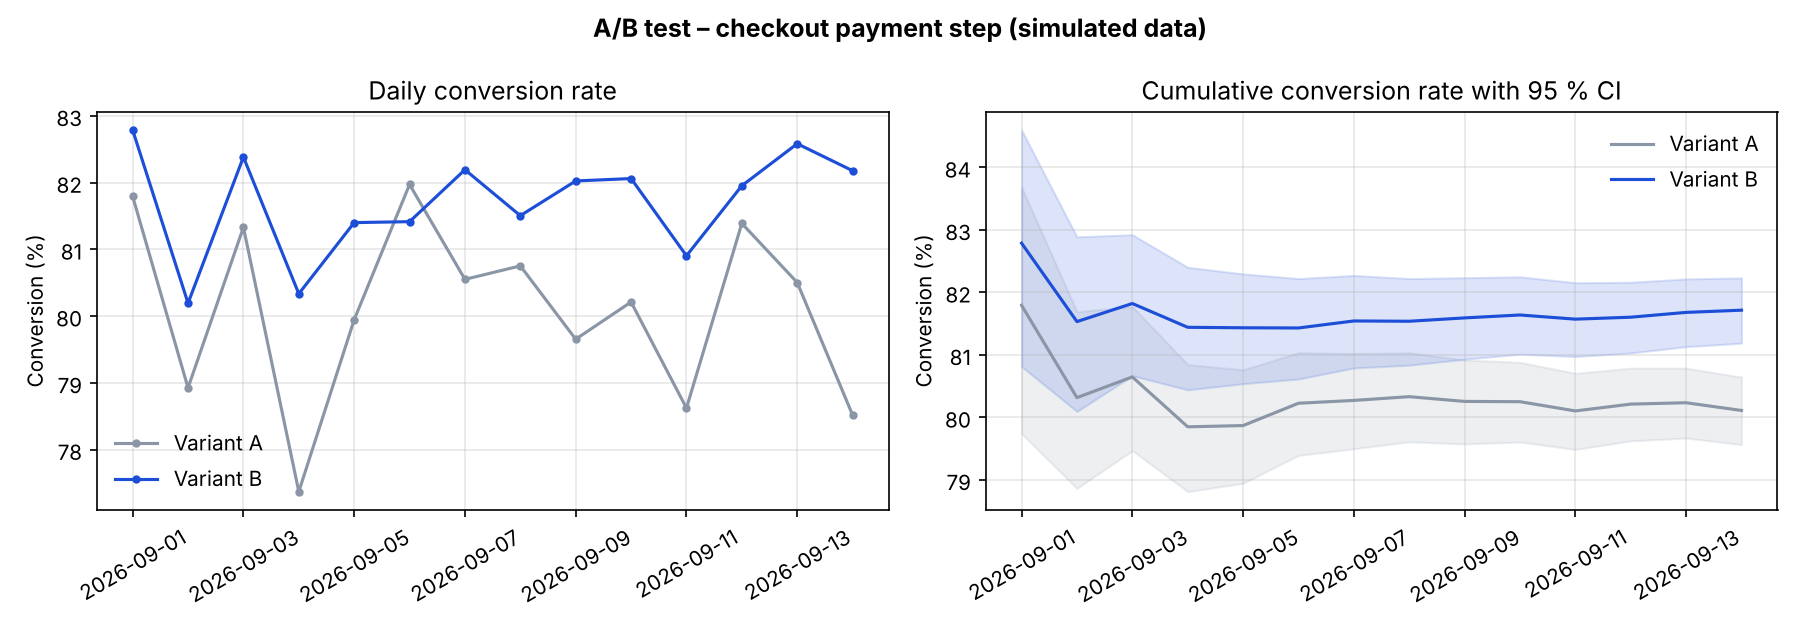

In [6]:
from IPython.display import Image
Image(plot(df, "ab_test_checkout.png"))

## Takeaways
* Variant B lifts checkout conversion by roughly **+1.6 pp (≈ +2 % relative)**, and the effect is statistically significant.
* The uplift comes almost entirely from **mobile**; on desktop the difference is within noise. Recommendation: ship B, and investigate what in the desktop flow stops the new step from helping there.
* With ~21 000 sessions per variant the test can detect ~1.1 pp. Effects smaller than that need more traffic or a longer test – decide this *before* the test starts.
* The same functions work on real session data: replace `simulate_sessions()` with a query that returns one row per session with `variant`, `device`, `date`, `converted`.